In [1]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

Device: cuda


In [2]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

train = datasets.MNIST("data", train=True, download=True,
                       transform=transforms.ToTensor())
test = datasets.MNIST("data", train=False, download=True,
                      transform=transforms.ToTensor())
loader = DataLoader(train, batch_size=128, shuffle=True)
print("Train images:", len(train), "| Test images:", len(test))

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 407kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.72MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.3MB/s]

Train images: 60000 | Test images: 10000


In [3]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mean = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)
        self.decoder = nn.Sequential(nn.Linear(2, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

xb, _ = next(iter(loader))
with torch.no_grad():
    g, m, lv = vae(xb.to(device))
print("Input batch:", tuple(xb.shape))
print("Mean / logvar:", tuple(m.shape), tuple(lv.shape))
print("Flattened reconstruction:", tuple(g.shape))

Input batch: (128, 1, 28, 28)
Mean / logvar: (128, 2) (128, 2)
Flattened reconstruction: (128, 784)


In [4]:
import math
import torch.nn.functional as F

history = []

for epoch in range(1, 6):
    vae.train()
    totals = dict(reconstruction=0.0, kl=0.0)
    for x, _ in loader:
        x = x.to(device)
        generated, mu, logvar = vae(x)
        recon = F.binary_cross_entropy(generated, x.flatten(1), reduction="sum")
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum()
        loss = (recon + kl) / x.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        totals["reconstruction"] += recon.item()
        totals["kl"] += kl.item()
    per_image = {k: round(v / len(train), 2) for k, v in totals.items()}
    history.append((epoch, per_image["reconstruction"], per_image["kl"]))
    print(epoch, per_image)

assert all(math.isfinite(r) and math.isfinite(k) for _, r, k in history),
torch.save(vae.state_dict(), out / "vae_mnist.pt")
print("Both losses finite. Checkpoint saved.")

1 {'reconstruction': 188.5, 'kl': 6.67}
2 {'reconstruction': 164.6, 'kl': 5.31}
3 {'reconstruction': 159.62, 'kl': 5.38}
4 {'reconstruction': 156.9, 'kl': 5.45}
5 {'reconstruction': 155.01, 'kl': 5.53}
Both losses finite. Checkpoint saved.


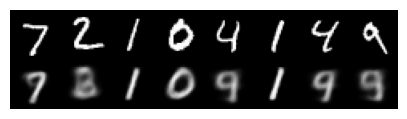

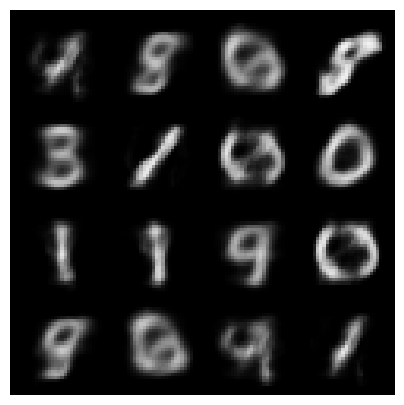

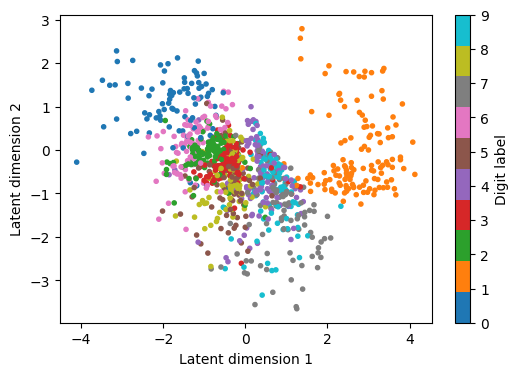

In [5]:
def show_grid(images, name, nrow=4):
    grid = make_grid(images.cpu(), nrow=nrow)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.savefig(out / name, bbox_inches="tight")
    plt.show()

vae.eval()
with torch.no_grad():
    x, y = next(iter(DataLoader(test, batch_size=1024)))
    mu, _ = vae.encode(x.to(device))
    recon = vae.decoder(mu[:8]).reshape(-1, 1, 28, 28)
    samples = vae.decoder(torch.randn(16, 2, device=device))
    show_grid(torch.cat([x[:8], recon.cpu()]), "vae_reconstructed.png", nrow=8)
    show_grid(samples.reshape(-1, 1, 28, 28), "vae_generated.png")
    coords = mu.cpu()

plt.figure(figsize=(6, 4))
plt.scatter(coords[:, 0], coords[:, 1], c=y.numpy(), cmap="tab10", s=9)
plt.colorbar(ticks=range(10), label="Digit label")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.savefig(out / "vae_latent.png", bbox_inches="tight")
plt.show()

In [6]:
print(f"{'Epoch':<6}{'Recon loss/image':<20}{'KL/image':<12}")
for e, r, k in history:
    if e in (1, 3, 5):
        print(f"{e:<6}{r:<20}{k:<12}")
print("\n outputs)")

Epoch Recon loss/image    KL/image    
1     188.5               6.67        
3     159.62              5.38        
5     155.01              5.53        

 outputs)
